# Week 2

### Setup

In [49]:
# pandas/numpy: data loading & manipulation
import numpy as np 
import pandas as pd

# matplotlib/seaborn: plotting
import matplotlib.pyplot as plt
import seaborn as sns

# sklearn: train/test split, scaling, logistic regression w/ L1 (lasso), metrics [later]
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import (
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

sns.set_style("whitegrid")

In [ ]:
df = pd.read_csv("diabetes_binary_health_indicators_BRFSS2015.csv") # load data

print(df.head())

# list of variables that are logically binary/categorical
binary_vars = [
    "Diabetes_binary", "HighBP", "HighChol", "CholCheck", "Smoker", "Stroke",
    "HeartDiseaseorAttack", "PhysActivity", "Fruits", "Veggies",
    "HvyAlcoholConsump", "AnyHealthcare", "NoDocbcCost", "DiffWalk", "Sex",
]


# convert those columns to pandas 'category' dtype
for col in binary_vars: 
    df[col] = df[col].astype("category")

In [ ]:
# Clean up code
# check missing values per column
print(df.isna().sum())

# remove rows with any missing values
df = df.dropna()

In [ ]:
# Scale numeric columns
# identify numeric (non-categorical) columns and standardize them (z-score),

# Keep original values for EDA
df_eda = df.copy()

# Scale a separate copy for modeling
df_model = df.copy()

numeric_cols = df_model.select_dtypes(include=[np.number]).columns
scaler = StandardScaler()
df_model[numeric_cols] = scaler.fit_transform(df_model[numeric_cols])

# summary statistics
print(df.describe(include="all"))

# ensure the target is categorical
df["Diabetes_binary"] = df["Diabetes_binary"].astype("category")

# frequency table + proportions for HighBP
print(df["HighBP"].value_counts())
print(df["HighBP"].value_counts(normalize=True))

### Exploratory Data Analysis

Checks class imbalance (amount of diabetes vs non-diabete individuals)

Diabetes_binary
0.0    218334
1.0     35346
Name: count, dtype: int64
Diabetes_binary
0.0    86.066698
1.0    13.933302
Name: proportion, dtype: float64


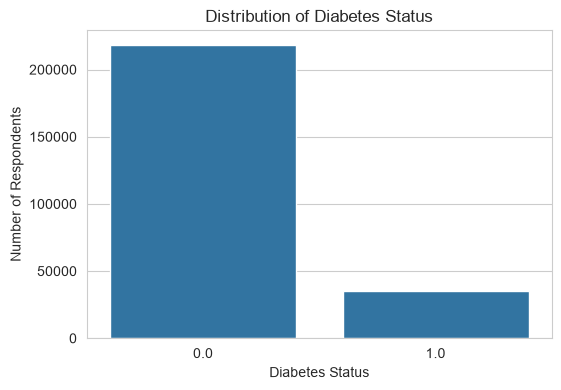

In [53]:
diabetes_counts = df_eda["Diabetes_binary"].value_counts()
diabetes_percent = df_eda["Diabetes_binary"].value_counts(normalize=True) * 100

print(diabetes_counts)
print(diabetes_percent)

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Diabetes_binary")
plt.title("Distribution of Diabetes Status")
plt.xlabel("Diabetes Status")
plt.ylabel("Number of Respondents")
plt.show()

## Diabetes prevalence by age group
### this shows the proportion of responses with diabetes in each age category.

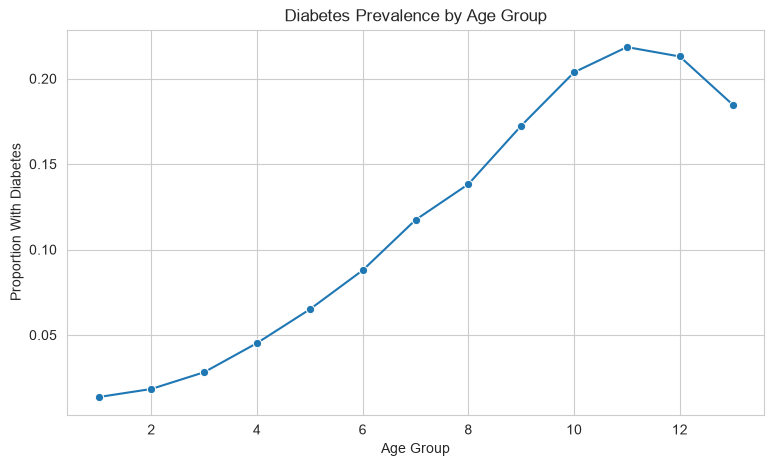

In [54]:
age_diabetes = (
    df.groupby("Age", observed=False)["Diabetes_binary"]
    .apply(lambda x: x.astype(int).mean())
    .reset_index(name="Diabetes_Rate")
)

plt.figure(figsize=(9, 5))
sns.lineplot(data=age_diabetes, x="Age", y="Diabetes_Rate", marker="o")
plt.title("Diabetes Prevalence by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Proportion With Diabetes")
plt.show()

## BMI distribution by diabetes status
### Compares BMI values for respondents with and without diabetes.

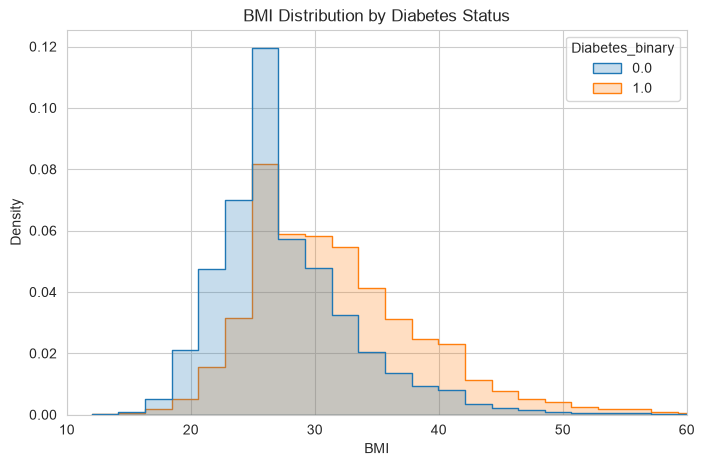

In [55]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_eda,
    x="BMI",
    hue="Diabetes_binary",
    bins=40,
    stat="density",
    common_norm=False,
    element="step"
)

plt.xlim(10, 60)
plt.title("BMI Distribution by Diabetes Status")
plt.xlabel("BMI")
plt.ylabel("Density")
plt.show()

## Diabetes prevalence across bmi categories
### BMI is divided into standard categories to make differences in diabetes easier to interpret.

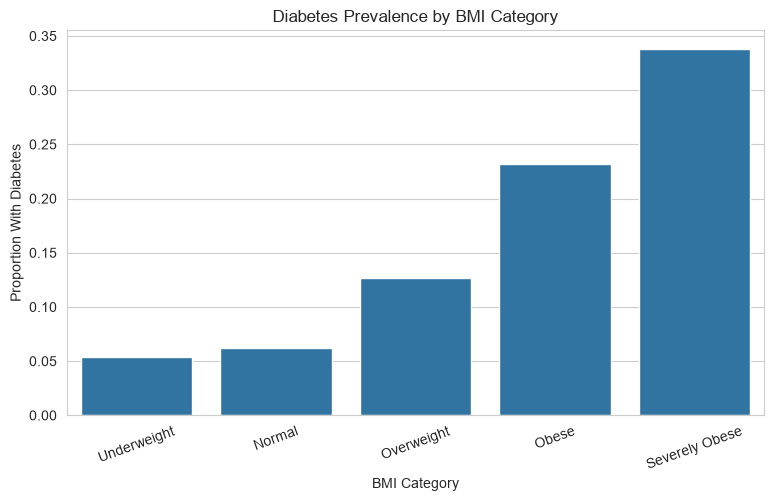

In [58]:
df_eda["BMI_Category"] = pd.cut(
    df_eda["BMI"],
    bins=[0, 18.5, 25, 30, 40, np.inf],
    labels=["Underweight", "Normal", "Overweight", "Obese", "Severely Obese"]
)

bmi_rates = (
    df_eda.groupby("BMI_Category", observed=False)["Diabetes_binary"]
    .apply(lambda x: x.astype(int).mean())
    .reset_index(name="Diabetes_Rate")
)

plt.figure(figsize=(9, 5))
sns.barplot(data=bmi_rates, x="BMI_Category", y="Diabetes_Rate")
plt.title("Diabetes Prevalence by BMI Category")
plt.xlabel("BMI Category")
plt.ylabel("Proportion With Diabetes")
plt.xticks(rotation=20)
plt.show()

## Combined effects of high blood pressure and high cholesterol
### Examines how high blood pressure and high cholestrol relate to diabetes when considered together.

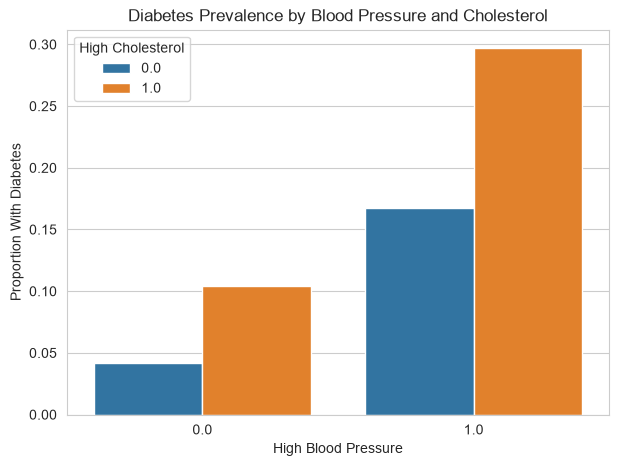

In [ ]:
combined_risk = (
    df.groupby(["HighBP", "HighChol"], observed=False)["Diabetes_binary"]
    .apply(lambda x: x.astype(int).mean())
    .reset_index(name="Diabetes_Rate")
)

plt.figure(figsize=(7, 5))
sns.barplot(
    data=combined_risk,
    x="HighBP",
    y="Diabetes_Rate",
    hue="HighChol"
)
plt.title("Diabetes Prevalence by Blood Pressure and Cholesterol")
plt.xlabel("High Blood Pressure")
plt.ylabel("Proportion With Diabetes")
plt.legend(title="High Cholesterol")
plt.show()

## Diabetes frequency by general health
### Shows wehther diabetes becomes more common as reported health worsens. 1 (Excellent) - 5 (Poor)

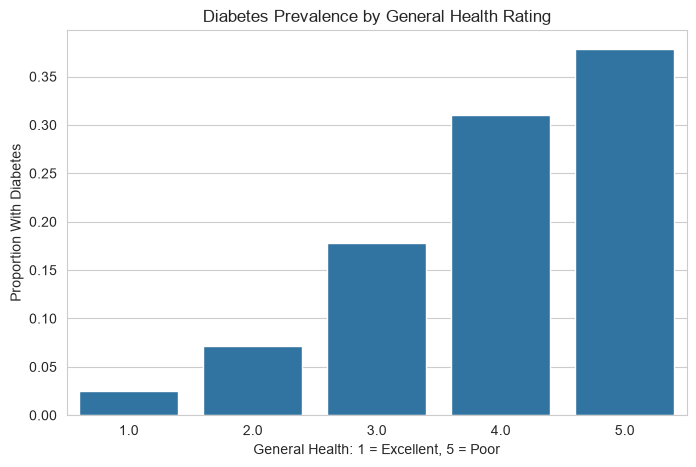

In [ ]:
genhealth_rates = (
    df.groupby("GenHlth", observed=False)["Diabetes_binary"]
    .apply(lambda x: x.astype(int).mean())
    .reset_index(name="Diabetes_Rate")
)

plt.figure(figsize=(8, 5))
sns.barplot(data=genhealth_rates, x="GenHlth", y="Diabetes_Rate")
plt.title("Diabetes Prevalence by General Health Rating")
plt.xlabel("General Health: 1 = Excellent, 5 = Poor")
plt.ylabel("Proportion With Diabetes")
plt.show()

## Correlation Heatmap
### Shows the strength and direction of relationships between the variables below. 
- Values closer to 1 indicate strong relationship
- Values closer to -1 indicate strong inverse relationship
- Values closer to 0 indicate weak relationship

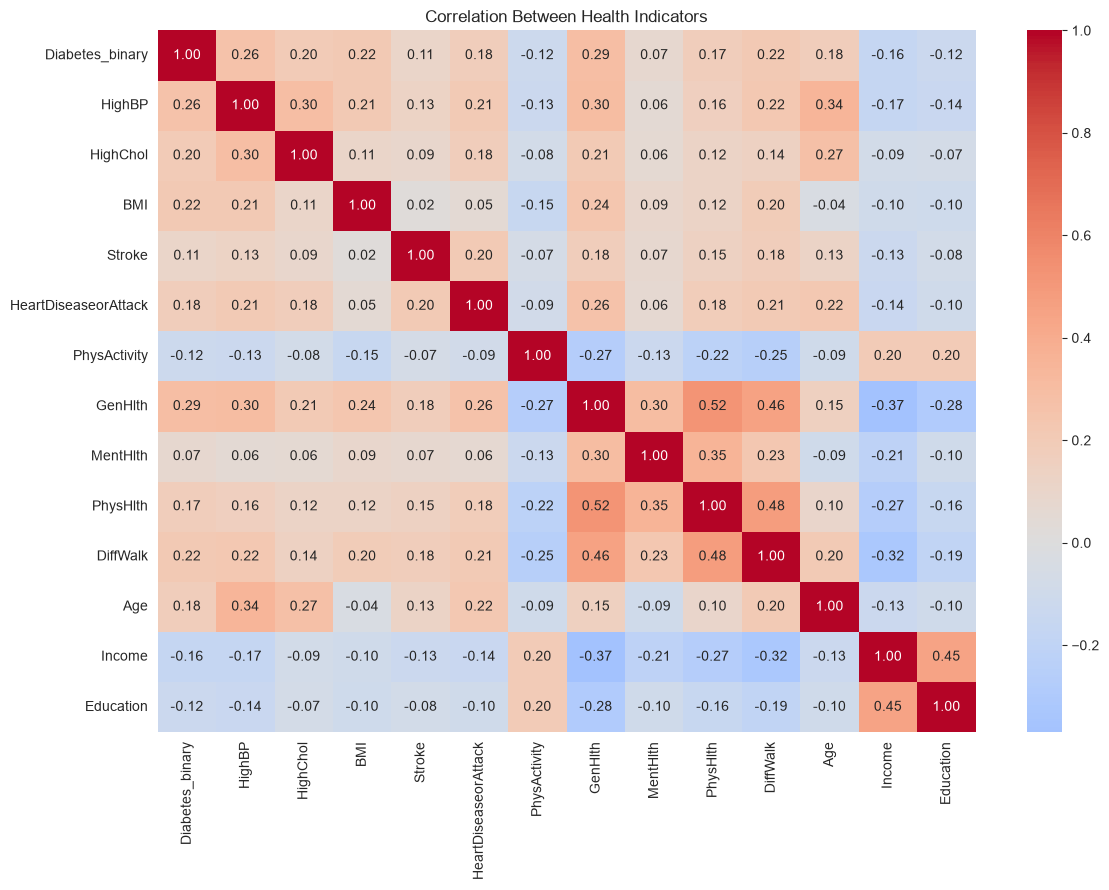

In [64]:
correlation_columns = [
    "Diabetes_binary", "HighBP", "HighChol", "BMI", "Stroke",
    "HeartDiseaseorAttack", "PhysActivity", "GenHlth",
    "MentHlth", "PhysHlth", "DiffWalk", "Age", "Income", "Education"
]

corr_data = df[correlation_columns].astype(float)
corr_matrix = corr_data.corr()

plt.figure(figsize=(12, 9))
sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f"
)
plt.title("Correlation Between Health Indicators")
plt.tight_layout()
plt.show()

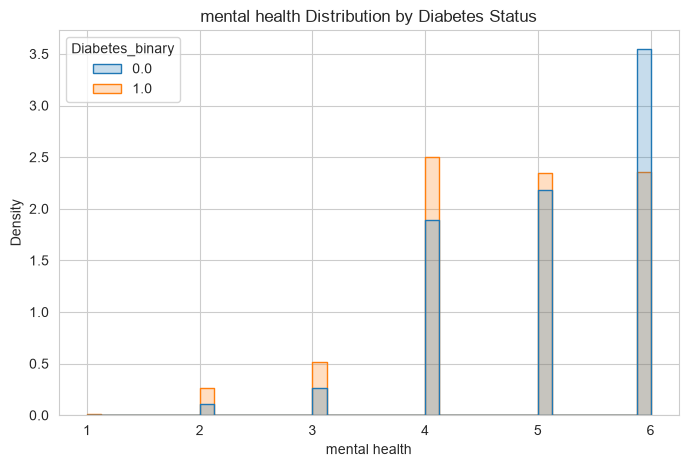

In [63]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_eda,
    x="Education",
    hue="Diabetes_binary",
    bins=40,
    stat="density",
    common_norm=False,
    element="step"
)

#plt.xlim(10, 20)
plt.title("mental health Distribution by Diabetes Status")
plt.xlabel("mental health")
plt.ylabel("Density")
plt.show()

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_eda,
    x="MentHlth",
    hue="Diabetes_binary",
    bins=40,
    stat="density",
    common_norm=False,
    element="step"
)

#plt.xlim(10, 20)
plt.title("mental health Distribution by Diabetes Status")
plt.xlabel("mental health")
plt.ylabel("Density")
plt.show()